# DATAFEST 2026 · #CodingChallenge — 03. Mejora del Gini: descubrimiento de las reglas del generador

**Punto de partida.** El modelo de `02_Modelado.ipynb` (LightGBM monótono, 5 semillas) obtiene Gini ≈ 0.257 en validación
temporal y parecía estar en el techo. Este notebook muestra que **no lo estaba**: la señal está en un conjunto pequeño
de **reglas de negocio con umbrales exactos** que un modelo de árboles aproxima con ruido, y que una regresión logística
con esas reglas estima casi sin pérdida.

| | LightGBM actual | **Logística con reglas** |
|---|---|---|
| Gini validación por cliente (ene–nov, 5 folds) | 0.264 | **0.270** |
| Gini validación temporal (ago–nov) | 0.257 | **0.264** |
| Parámetros | ~400 árboles × 8 hojas | **~30 coeficientes interpretables** |
| Techo teórico estimado | — | 0.274 |

**Hoja de ruta.** (1) Un esquema de validación más preciso para medir mejoras pequeñas · (2) diagnóstico de por qué el
*boosting* se estanca · (3) descubrimiento de reglas con tablas y minería sistemática de residuos · (4) modelo de reglas
y comparación · (5) robustez · (6) techo alcanzable · (7) entrega.

## 0. Configuración

In [1]:
import itertools, json, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA_DIR, FIG_DIR, ART_DIR = Path("."), Path("figures"), Path("artifacts")
SEED, N_JOBS = 42, 8
TARGET, ID = "objetivo", "id_cliente"
CAT = ["ocupacion", "region", "canal_adquisicion", "banda_riesgo", "dispositivo_principal"]
BOOL = ["tiene_tarjeta_credito", "activo_movil", "es_nuevo_cliente", "tiene_prestamo", "tiene_seguro"]

C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#8a8984", "red": "#e34948",
     "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
SERIES = [C["blue"], C["orange"], C["aqua"]]
plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": C["ink2"], "axes.edgecolor": C["grid"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": C["grid"], "grid.linewidth": 0.7,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "text.color": C["ink"],
    "legend.frameon": False, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=SERIES),
})
savefig = lambda fig, name: fig.savefig(FIG_DIR / f"{name}.png")
gini = lambda y, s: 2 * roc_auc_score(y, s) - 1

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

df = pd.concat([train, test], ignore_index=True)
df["t"] = df["mes"] % 100
df = df.sort_values([ID, "t"]).reset_index(drop=True)
df["meses_en_panel"] = df.groupby(ID).cumcount()          # solo pasado: meses previos observados
for c in CAT: df[c] = df[c].astype("category")
for c in BOOL: df[c] = df[c].astype(int)
dev = df[df[TARGET].notna()].copy(); dev[TARGET] = dev[TARGET].astype(int)
tst = df[df[TARGET].isna()].copy()

LGB_FINAL = json.load(open(ART_DIR / "modelo_final.json"))
FEATURES_LGB, LGB_PARAMS = LGB_FINAL["features"], {**LGB_FINAL["lgbm_params"], "n_jobs": N_JOBS}
print(f"desarrollo: {dev.shape} | test: {tst.shape} | positivos en desarrollo: {dev[TARGET].sum():,}")

desarrollo: (110100, 27) | test: (9900, 27) | positivos en desarrollo: 16,567


## 1. Un esquema de validación capaz de medir mejoras de 0.005

La validación temporal de `02` evalúa 4 meses (~6.000 positivos): su error estándar del Gini medio es ≈ 0.007, del mismo
orden que las mejoras que buscamos. Como el EDA mostró que **todas las variables son estáticas por cliente y no hay
drift**, se puede validar también con **GroupKFold por cliente sobre los 11 meses** (16.600 positivos): ningún cliente
aparece en entrenamiento y validación a la vez, y el Gini se calcula **dentro de cada mes** (igual que en el test de
diciembre) y se promedia.

- **Validación por cliente**: para explorar y comparar (precisa, rápida).
- **Validación temporal ago–nov**: para confirmar con el escenario real (entrenar con el pasado, predecir el mes siguiente).

In [3]:
FOLDS = list(GroupKFold(n_splits=5, shuffle=True, random_state=0).split(dev, groups=dev[ID]))
RES_G, RES_T, OOF = {}, {}, {}

def gini_mensual(score, d=dev):
    return pd.Series({m: gini(d[TARGET].values[(d.t == m).values], score[(d.t == m).values]) for m in sorted(d.t.unique())})

def cv_cliente(name, fit_predict, folds=FOLDS, verbose=True):
    oof = np.zeros(len(dev))
    for tr_i, va_i in folds:
        oof[va_i] = fit_predict(dev.iloc[tr_i], dev.iloc[va_i])
    OOF[name] = oof; RES_G[name] = gini_mensual(oof).mean()
    if verbose: print(f"{name:42s} Gini por cliente = {RES_G[name]:.4f}")
    return oof

def cv_temporal(name, fit_predict, months=(8, 9, 10, 11)):
    s = pd.Series({m: gini(dev.loc[dev.t == m, TARGET], fit_predict(dev[dev.t < m], dev[dev.t == m])) for m in months})
    RES_T[name] = s
    print(f"{name:42s} Gini temporal = {s.mean():.4f}  | " + "  ".join(f"{v:.4f}" for v in s))
    return s

def make_lgb(params, feats=FEATURES_LGB, seeds=(0,)):
    def fp(a, b):
        return np.mean([lgb.LGBMClassifier(**{**params, "random_state": s}).fit(a[feats], a[TARGET])
                        .predict_proba(b[feats])[:, 1] for s in seeds], axis=0)
    return fp

cv_cliente("LGBM actual (1 semilla)", make_lgb(LGB_PARAMS))
alt = list(GroupKFold(n_splits=5, shuffle=True, random_state=1).split(dev, groups=dev[ID]))
cv_cliente("LGBM actual · otra partición de folds", make_lgb(LGB_PARAMS), alt);

LGBM actual (1 semilla)                    Gini por cliente = 0.2643


LGBM actual · otra partición de folds      Gini por cliente = 0.2646


**Lectura.** Cambiar la partición de folds mueve el Gini en ~0.0003: el esquema por cliente distingue diferencias de
milésimas, algo imposible con 4 meses temporales.

## 2. ¿Por qué el *boosting* se estanca?

### 2.1 La señal vive en interacciones
Se compara el mismo LightGBM restringido a ser **aditivo** (árboles de 1 corte), con interacciones de orden 2 (profundidad 2)
y el modelo actual (8 hojas).

In [4]:
B = dict(verbose=-1, n_jobs=N_JOBS, subsample_freq=1, subsample=0.7, colsample_bytree=0.5, reg_lambda=10, min_child_samples=200)
cv_cliente("LGBM aditivo (stumps)", make_lgb({**B, "num_leaves": 2, "n_estimators": 1500, "learning_rate": 0.05}))
cv_cliente("LGBM profundidad 2", make_lgb({**B, "max_depth": 2, "num_leaves": 4, "n_estimators": 1000, "learning_rate": 0.03}))
print(f"{'LGBM actual (8 hojas)':42s} Gini por cliente = {RES_G['LGBM actual (1 semilla)']:.4f}")

LGBM aditivo (stumps)                      Gini por cliente = 0.2359


LGBM profundidad 2                         Gini por cliente = 0.2565
LGBM actual (8 hojas)                      Gini por cliente = 0.2643


**Lectura.** Sin interacciones el Gini cae a ≈ 0.236: casi una décima parte de la señal está en **combinaciones** de
variables. Un *boosting* aprende esas combinaciones partiendo el espacio en muchas hojas pequeñas, y cada hoja estima su
tasa con pocas observaciones → varianza. Si las combinaciones reales son pocas y nítidas, **escribirlas explícitamente**
debería estimarlas mucho mejor.

### 2.2 ¿Cuánto Gini pierde el pipeline por error de estimación? (*bootstrap* paramétrico)
Se toma como "verdad" la probabilidad del propio LightGBM entrenado con toda la data, se simulan etiquetas
Bernoulli con esa probabilidad y se re-entrena el pipeline completo: la diferencia entre el Gini de la probabilidad
verdadera (oráculo) y el recuperado es la pérdida por estimación.

In [5]:
rng = np.random.default_rng(SEED)
p_lgb = np.mean([lgb.LGBMClassifier(**{**LGB_PARAMS, "random_state": s}).fit(dev[FEATURES_LGB], dev[TARGET])
                 .predict_proba(dev[FEATURES_LGB])[:, 1] for s in range(3)], axis=0)
rows = []
for rep in range(2):
    ys = rng.binomial(1, p_lgb)
    oof = np.zeros(len(dev))
    for tr_i, va_i in FOLDS:
        oof[va_i] = lgb.LGBMClassifier(**{**LGB_PARAMS, "random_state": 0}).fit(dev.iloc[tr_i][FEATURES_LGB], ys[tr_i]) \
                       .predict_proba(dev.iloc[va_i][FEATURES_LGB])[:, 1]
    d_ = dev.assign(**{TARGET: ys})
    rows.append({"Gini oráculo": gini_mensual(p_lgb, d_).mean(), "Gini recuperado": gini_mensual(oof, d_).mean()})
boot = pd.DataFrame(rows); boot["pérdida"] = boot["Gini oráculo"] - boot["Gini recuperado"]
boot.loc["media"] = boot.mean(); boot

,Gini oráculo,Gini recuperado,pérdida
0,0.2467,0.2379,0.0089
1,0.2426,0.2344,0.0082
media,0.2447,0.2361,0.0086


**Lectura.** Dos hallazgos:
1. El pipeline de *boosting* pierde **≈ 0.01 de Gini** solo por error de estimación.
2. El Gini oráculo bajo la "verdad" del LightGBM (≈ 0.245) es **menor** que el Gini que el propio LightGBM logra en la
   data real (0.264): la probabilidad del modelo está **más aplanada que la realidad**. La señal verdadera es más fuerte
   de lo que el *boosting* captura → el techo de 0.26 del notebook 02 era del **método**, no de la data.

## 3. Descubrimiento de las reglas

### 3.1 Tablas de tasas por segmento
La importancia por interacción (pares de cortes en un mismo camino del árbol) concentra el 80% de la ganancia en
cinco variables: `banda_riesgo`, `numero_productos`, `dias_ultima_transaccion`, `activo_movil`, `tiene_tarjeta_credito`.
Se tabula la tasa de conversión en sus combinaciones.

In [6]:
riesgo = dev.banda_riesgo.astype(str)
mc = np.where((dev.activo_movil == 1) & (dev.tiene_tarjeta_credito == 1), "móvil + tarjeta", "resto")
print("Tasa de conversión · riesgo × (móvil y tarjeta) × número de productos")
display(dev.pivot_table(index=[riesgo.rename("riesgo"), pd.Series(mc, index=dev.index, name="móvil/tarjeta")],
                        columns="numero_productos", values=TARGET, aggfunc="mean", observed=True))
rec = pd.Series(np.where(dev.dias_ultima_transaccion <= 180, "≤ 180 días", "> 180 días"), index=dev.index, name="recencia")
print("Tasa de conversión · canal × riesgo × recencia de la última transacción")
display(dev.pivot_table(index="canal_adquisicion", columns=[riesgo.rename("riesgo"), rec], values=TARGET,
                        aggfunc="mean", observed=True).round(3))

Tasa de conversión · riesgo × (móvil y tarjeta) × número de productos


numero_productos            1      2      3      4      5
riesgo móvil/tarjeta                                     
high   móvil + tarjeta 0.0877 0.0789 0.0968 0.1045 0.1230
       resto           0.0830 0.0859 0.0850 0.0930 0.0917
low    móvil + tarjeta 0.1435 0.2583 0.3700 0.3842 0.3920
       resto           0.1319 0.1339 0.2362 0.2362 0.2561
medium móvil + tarjeta 0.1341 0.1400 0.1549 0.1697 0.1541
       resto           0.1377 0.1313 0.1411 0.1475 0.1487

Tasa de conversión · canal × riesgo × recencia de la última transacción


riesgo                  high                   low                medium           
recencia          > 180 días ≤ 180 días > 180 días ≤ 180 días > 180 días ≤ 180 días
canal_adquisicion                                                                  
branch                0.0160     0.1070     0.1720     0.1930     0.1300     0.1460
call_center           0.0530     0.1450     0.1900     0.2000     0.1350     0.1570
mobile                0.0590     0.1470     0.1750     0.1950     0.1320     0.1500
partner               0.0600     0.1440     0.1650     0.1900     0.1270     0.1440
web                   0.0510     0.1500     0.1770     0.2020     0.1330     0.1490

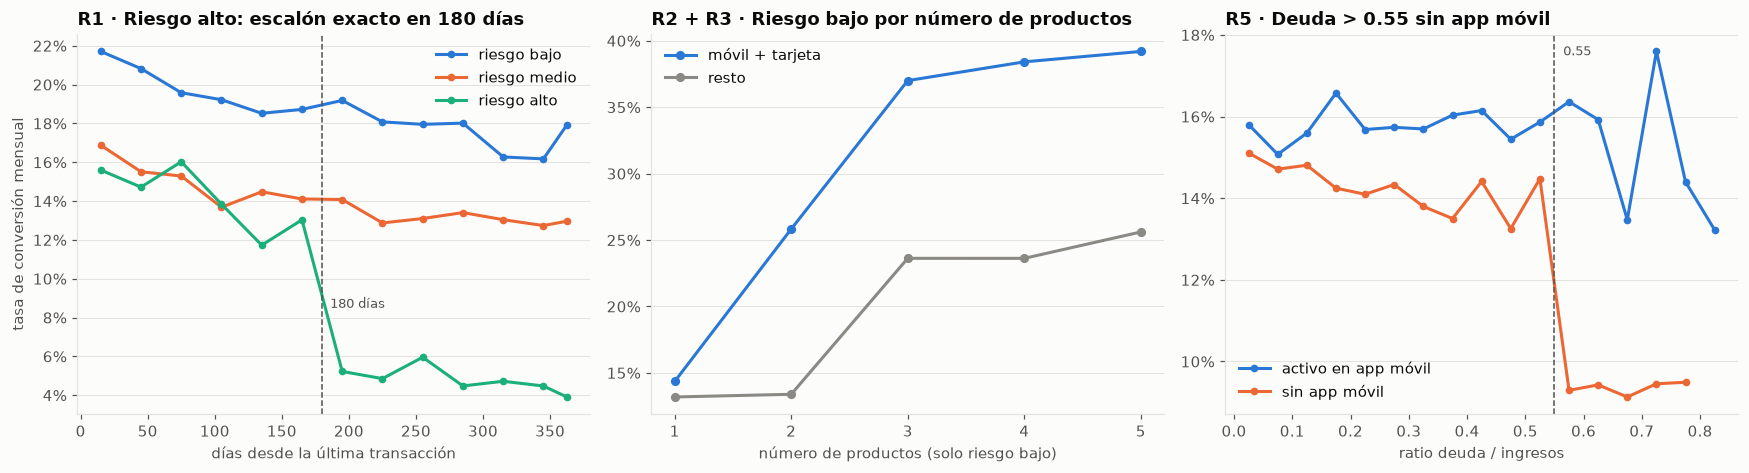

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]
bins = np.r_[np.arange(0, 361, 30), 365]
for r_, col in zip(["low", "medium", "high"], SERIES):
    nombre_r = {"low": "bajo", "medium": "medio", "high": "alto"}[r_]
    s = dev[riesgo == r_].groupby(pd.cut(dev.dias_ultima_transaccion[riesgo == r_], bins), observed=True)[TARGET].mean()
    ax.plot([iv.mid for iv in s.index], s.values, marker="o", markersize=4, color=col, label=f"riesgo {nombre_r}")
ax.axvline(180, color=C["ink2"], linestyle="--", linewidth=1); ax.text(186, 0.085, "180 días", color=C["ink2"], fontsize=8.5)
ax.set_xlabel("días desde la última transacción"); ax.set_ylabel("tasa de conversión mensual")
ax.set_title("R1 · Riesgo alto: escalón exacto en 180 días"); ax.legend(loc="upper right")

ax = axes[1]
low = dev[riesgo == "low"]
mc_low = (low.activo_movil == 1) & (low.tiene_tarjeta_credito == 1)
for msk, lab, col in [(mc_low, "móvil + tarjeta", C["blue"]), (~mc_low, "resto", C["gray"])]:
    s = low[msk].groupby("numero_productos")[TARGET].mean()
    ax.plot(s.index, s.values, marker="o", markersize=5, color=col, label=lab)
ax.set_xticks(range(1, 6)); ax.set_xlabel("número de productos (solo riesgo bajo)")
ax.set_title("R2 + R3 · Riesgo bajo por número de productos"); ax.legend(loc="upper left")

ax = axes[2]
bins = np.round(np.arange(0.0, 1.0001, 0.05), 2)
for v, lab, col in [(1, "activo en app móvil", C["blue"]), (0, "sin app móvil", C["orange"])]:
    d_ = dev[dev.activo_movil == v]
    s = d_.groupby(pd.cut(d_.ratio_deuda_ingresos, bins), observed=True)[TARGET].agg(["mean", "size"])
    s = s[s["size"] >= 150]
    ax.plot([iv.mid for iv in s.index], s["mean"].values, marker="o", markersize=4, color=col, label=lab)
ax.axvline(0.55, color=C["ink2"], linestyle="--", linewidth=1); ax.text(0.565, 0.175, "0.55", color=C["ink2"], fontsize=8.5)
ax.set_xlabel("ratio deuda / ingresos"); ax.set_title("R5 · Deuda > 0.55 sin app móvil"); ax.legend(loc="lower left")
for ax, paso in zip(axes, [0.02, 0.05, 0.02]):
    ax.yaxis.set_major_locator(plt.MultipleLocator(paso)); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); savefig(fig, "19_reglas_descubiertas")

**Lectura: el generador se comporta como un sistema de reglas con umbrales exactos.**

| Regla | Condición | Efecto en la tasa |
|---|---|---|
| R1 | riesgo alto **y** última transacción ≤ 180 días | ≈ +9 pp (0.05 → 0.14) |
| R2 | riesgo bajo **y** ≥ 3 productos | ≈ +10 pp |
| R3 | riesgo bajo **y** activo en app **y** tarjeta **y** ≥ 2 productos | ≈ +12 pp, se suma a R2 |
| R4 | riesgo alto **y** adquirido en agencia (`branch`) | ≈ −4 pp |
| R5 | ratio deuda/ingresos > 0.55 **y** sin app móvil | ≈ −5 pp |

Además, la recencia transaccional tiene un declive suave en todos los segmentos, y entre canales solo `branch` se
distingue (los otros cuatro son equivalentes). Los efectos son aproximadamente **aditivos en la escala de probabilidad**
(p. ej. R4 resta ≈ 4 pp tanto con recencia ≤180 como >180), lo que explica por qué un modelo en log-odds sin las reglas
explícitas necesita muchas interacciones para imitarlos. R4 y R5 se detectaron con la minería de residuos de la
sección 3.2 (la tabla de canal confirma R4).

### 3.2 Minería sistemática de residuos
Para no depender de la intuición, se discretiza cada variable (quintiles o categorías) y se prueban **todas las celdas
de los 231 pares y 300 tríos** contra el residuo de un modelo: el estadístico es un χ² estandarizado (z ≈ 0 si el
modelo ya captura todo; z > 4 indica una regla no capturada, controlando por pruebas múltiples).

In [8]:
def disc(d):
    D, lab = {}, {}
    for c in ["banda_riesgo", "ocupacion", "region", "canal_adquisicion", "dispositivo_principal", "activo_movil",
              "tiene_tarjeta_credito", "tiene_prestamo", "tiene_seguro", "es_nuevo_cliente", "numero_productos"]:
        cat = pd.Categorical(d[c].astype(str)); D[c] = cat.codes.astype(np.int64); lab[c] = list(cat.categories)
    for c in ["edad", "ingresos", "antiguedad_cuenta_meses", "saldo_promedio", "antiguedad_direccion_meses",
              "visitas_web_ultimos_90_dias", "distancia_sucursal_km", "dia_preferido_pago", "ratio_deuda_ingresos",
              "dias_ultima_transaccion", "meses_en_panel"]:
        D[c] = pd.qcut(d[c].rank(method="first"), 5, labels=False).values.astype(np.int64); lab[c] = [f"q{i+1}" for i in range(5)]
    return D, lab
DISC, LAB = disc(dev)

def mineria_residuos(oof, top=8):
    r = dev[TARGET].values - oof
    r = r - pd.Series(r).groupby(dev.t.values).transform("mean").values      # quita el nivel de cada mes
    w = oof * (1 - oof)
    def scan(keys):
        k = np.zeros(len(r), np.int64); mult = 1
        for c in keys: k += DISC[c] * mult; mult *= 10
        n, sr, sw = np.bincount(k), np.bincount(k, r), np.bincount(k, w)
        ok = n >= 300; z = sr[ok] / np.sqrt(sw[ok]); idx = np.flatnonzero(ok); j = np.abs(z).argmax(); code_ = idx[j]
        cell = []
        for c in keys: cell.append(f"{c}={LAB[c][code_ % 10]}"); code_ //= 10
        return ((z ** 2).sum() - len(z)) / np.sqrt(2 * len(z)), z[j], " & ".join(cell)
    cols = list(DISC)
    core = ["banda_riesgo", "numero_productos", "dias_ultima_transaccion", "activo_movil", "tiene_tarjeta_credito", "canal_adquisicion"]
    combos = [(a, b) for a, b in itertools.combinations(cols, 2)] + \
             [(a, b, c) for a, b in itertools.combinations(core, 2) for c in cols if c not in (a, b)]
    out = pd.DataFrame([(" × ".join(k),) + scan(list(k)) for k in combos], columns=["combinación", "z global", "z celda extrema", "celda extrema"])
    return out.sort_values("z global", ascending=False).head(top).reset_index(drop=True)

### 3.3 Modelo de reglas
Las reglas se codifican como indicadores, junto con los efectos principales que las componen (para que cada regla mida
solo su efecto incremental) y una forma suave de la recencia (√días, que ajusta mejor que la lineal).

In [9]:
def X_reglas(d, menores=("ingresos", "antiguedad_cuenta_meses", "edad", "saldo_promedio", "distancia_sucursal_km", "tiene_prestamo"),
             dummies=("ocupacion", "region"), r4r5=True):
    r = d.banda_riesgo.astype(str)
    alto, bajo = (r == "high").astype(int), (r == "low").astype(int)
    p, dt = d.numero_productos, d.dias_ultima_transaccion
    mv, tc = d.activo_movil, d.tiene_tarjeta_credito
    mc, branch = mv * tc, (d.canal_adquisicion.astype(str) == "branch").astype(int)
    rec, deuda55 = (dt <= 180).astype(int), (d.ratio_deuda_ingresos > 0.55).astype(int)
    o = pd.DataFrame({
        # efectos principales
        "riesgo_alto": alto, "riesgo_bajo": bajo, "productos": p, "prod_ge2": (p >= 2).astype(int), "prod_ge3": (p >= 3).astype(int),
        "rec_le180": rec, "sqrt_dias_trans": np.sqrt(dt), "activo_movil": mv, "tiene_tarjeta": tc, "movil_y_tarjeta": mc,
        "bajo_x_movil_tarjeta": bajo * mc, "deuda55_x_no_alto": deuda55 * (1 - alto),
        # reglas
        "R1_alto_x_rec180": alto * rec,
        "R2_bajo_x_prod3": bajo * (p >= 3),
        "R3_bajo_x_movil_tarjeta_x_prod2": bajo * mc * (p >= 2),
    }, index=d.index)
    if r4r5:
        o["branch"] = branch
        o["R4_alto_x_branch"] = alto * branch
        o["R5_deuda55_x_sin_movil"] = deuda55 * (1 - mv)
    for c in menores: o[c] = d[c]
    if dummies: o = o.join(pd.get_dummies(d[list(dummies)].astype(str), drop_first=True).astype(int))
    return o

def make_logit(Xf, C_=0.1):
    def fp(a, b):
        Xa, Xb = Xf(a), Xf(b); sc = StandardScaler().fit(Xa)
        return LogisticRegression(C=C_, max_iter=3000).fit(sc.transform(Xa), a[TARGET]).predict_proba(sc.transform(Xb))[:, 1]
    return fp

TODAS = ("edad", "ingresos", "antiguedad_cuenta_meses", "saldo_promedio", "antiguedad_direccion_meses", "visitas_web_ultimos_90_dias",
         "distancia_sucursal_km", "dia_preferido_pago", "tiene_prestamo", "tiene_seguro", "es_nuevo_cliente", "meses_en_panel")
DUMS = ("ocupacion", "region", "canal_adquisicion", "dispositivo_principal")
oof_r3 = cv_cliente("Logística · reglas R1–R3 + todas las variables", make_logit(lambda d: X_reglas(d, TODAS, DUMS, r4r5=False)))
print("\nMinería de residuos sobre el modelo con R1–R3:")
display(mineria_residuos(oof_r3))

Logística · reglas R1–R3 + todas las variables Gini por cliente = 0.2653

Minería de residuos sobre el modelo con R1–R3:


,combinación,z global,z celda extrema,celda extrema
0,banda_riesgo × canal_adquisicion,7.0851,-6.2531,banda_riesgo=high & canal_adquisicion=branch
1,banda_riesgo × canal_adquisicion × es_nuevo_cl...,6.1569,-6.1500,banda_riesgo=high & canal_adquisicion=branch &...
2,banda_riesgo × canal_adquisicion × tiene_seguro,5.6650,-4.7873,banda_riesgo=high & canal_adquisicion=branch &...
3,activo_movil × canal_adquisicion × banda_riesgo,5.0666,-4.9609,activo_movil=1 & canal_adquisicion=branch & ba...
4,banda_riesgo × canal_adquisicion × activo_movil,5.0666,-4.9609,banda_riesgo=high & canal_adquisicion=branch &...
5,banda_riesgo × activo_movil × canal_adquisicion,5.0666,-4.9609,banda_riesgo=high & activo_movil=1 & canal_adq...
6,banda_riesgo × canal_adquisicion × visitas_web...,4.9878,-4.4058,banda_riesgo=high & canal_adquisicion=branch &...
7,banda_riesgo × canal_adquisicion × ingresos,4.6358,-4.1018,banda_riesgo=high & canal_adquisicion=branch &...


**Lectura.** Con R1–R3 el modelo ya supera al LightGBM, pero la minería detecta dos combinaciones con z muy por encima
del ruido: **riesgo alto × canal `branch`** y **sin app móvil × deuda alta** → reglas R4 y R5. Se agregan y se repite la
minería.

In [10]:
oof_r5 = cv_cliente("Logística · reglas R1–R5 + todas las variables", make_logit(lambda d: X_reglas(d, TODAS, DUMS)))
print("\nMinería de residuos sobre el modelo con R1–R5:")
display(mineria_residuos(oof_r5))

Logística · reglas R1–R5 + todas las variables Gini por cliente = 0.2678

Minería de residuos sobre el modelo con R1–R5:


,combinación,z global,z celda extrema,celda extrema
0,dias_ultima_transaccion × tiene_tarjeta_credit...,2.3066,-3.1532,dias_ultima_transaccion=q1 & tiene_tarjeta_cre...
1,dias_ultima_transaccion × activo_movil × ratio...,2.1310,3.1437,dias_ultima_transaccion=q1 & activo_movil=0 & ...
2,numero_productos × canal_adquisicion × dia_pre...,1.9793,3.0179,numero_productos=4 & canal_adquisicion=mobile ...
3,numero_productos × dias_ultima_transaccion × d...,1.9711,-2.9701,numero_productos=1 & dias_ultima_transaccion=q...
4,dias_ultima_transaccion × activo_movil × antig...,1.8074,-3.2569,dias_ultima_transaccion=q5 & activo_movil=0 & ...
5,dispositivo_principal × meses_en_panel,1.6620,-2.7900,dispositivo_principal=web & meses_en_panel=q5
6,numero_productos × canal_adquisicion × visitas...,1.5121,2.2746,numero_productos=2 & canal_adquisicion=web & v...
7,activo_movil × tiene_tarjeta_credito × distanc...,1.4984,-3.0008,activo_movil=0 & tiene_tarjeta_credito=1 & dis...


**Lectura.** Tras R4–R5 el z global máximo cae de 7.1 a ≈ 2.3 y ninguna celda supera |z| ≈ 3.3, lo esperable por azar
entre 531 combinaciones: **no queda estructura detectable** a esta resolución.

### 3.4 ¿Los umbrales son exactos?
Se barre cada umbral y se mide el ajuste (reducción de la suma de cuadrados, en unidades de χ²; 0 = mejor umbral).

In [11]:
y_ = dev[TARGET].values.astype(float)
X0 = X_reglas(dev).astype(float)
def sse(X):
    A = np.column_stack([np.ones(len(X)), X.values]); b, *_ = np.linalg.lstsq(A, y_, rcond=None); return ((y_ - A @ b) ** 2).sum()
sig2 = sse(X0) / len(y_)
alto = (dev.banda_riesgo.astype(str) == "high").astype(int); bajo = (dev.banda_riesgo.astype(str) == "low").astype(int)
dt_, de_, mv_, p_ = dev.dias_ultima_transaccion, dev.ratio_deuda_ingresos, dev.activo_movil, dev.numero_productos
barridos = {
    "R1 · días de recencia": ([150, 170, 175, 178, 180, 182, 185, 190, 210],
                              lambda X, g: X.assign(R1_alto_x_rec180=alto * (dt_ <= g), rec_le180=(dt_ <= g).astype(int))),
    "R5 · ratio deuda": ([0.45, 0.50, 0.53, 0.54, 0.55, 0.56, 0.58, 0.60, 0.65],
                         lambda X, g: X.assign(R5_deuda55_x_sin_movil=(de_ > g) * (1 - mv_), deuda55_x_no_alto=(de_ > g) * (1 - alto))),
    "R2 · productos ≥": ([2, 3, 4], lambda X, g: X.assign(R2_bajo_x_prod3=bajo * (p_ >= g))),
}
for nombre, (grid, f) in barridos.items():
    s = pd.Series({g: (sse(f(X0.copy(), g)) - 0) for g in grid}); s = (s - s.min()) / sig2
    print(f"{nombre:24s} mejor = {s.idxmin():>5}  | " + "  ".join(f"{k}: {v:5.1f}" for k, v in s.items()))

R1 · días de recencia    mejor =   180  | 150:  60.1  170:  22.0  175:   7.5  178:   3.4  180:   0.0  182:   4.3  185:   7.1  190:  21.9  210:  74.6


R5 · ratio deuda         mejor =  0.55  | 0.45:  36.6  0.5:  28.8  0.53:  13.1  0.54:   1.4  0.55:   0.0  0.56:  13.2  0.58:  14.0  0.6:  25.1  0.65:  43.0


R2 · productos ≥         mejor =     3  | 2: 272.5  3:   0.0  4: 242.6


**Lectura.** Los mínimos caen exactamente en **180 días, 0.55 y 3 productos**, con deterioros grandes al alejarse:
son umbrales de diseño del generador, no artefactos de muestreo.

## 4. Modelo final de reglas y comparación

Se poda el modelo con una regresión lineal de probabilidad con **errores agrupados por cliente** (cada cliente aporta
varias filas idénticas): se conservan las reglas y las variables menores con |t| > 2. Las demás (`meses_en_panel`,
dispositivo, seguro, visitas web, día de pago, antigüedad de dirección, cliente nuevo) tienen |t| < 1. El canal entra
solo como indicador `branch` (sección 3.1).

In [12]:
Xf = X_reglas(dev, TODAS, ("ocupacion", "region", "dispositivo_principal")).astype(float)
for m_ in range(2, 12): Xf[f"_mes_{m_}"] = (dev.t == m_).astype(float)        # controla el nivel de cada mes
Xf.insert(0, "constante", 1.0)
A = Xf.values; beta, *_ = np.linalg.lstsq(A, y_, rcond=None); e = y_ - A @ beta
XtXi = np.linalg.pinv(A.T @ A); g_ = pd.factorize(dev[ID])[0]
S = np.zeros((g_.max() + 1, A.shape[1])); np.add.at(S, g_, A * e[:, None])
se = np.sqrt(np.diag(XtXi @ (S.T @ S) @ XtXi))
coef = pd.DataFrame({"efecto (pp de probabilidad)": beta * 100, "t (agrupado por cliente)": beta / se}, index=Xf.columns)
coef = coef[~coef.index.str.startswith("_mes_") & (coef.index != "constante")].dropna()
coef.loc[[i for i in coef.index if i.startswith("R")]].round(2)

,efecto (pp de probabilidad),t (agrupado por cliente)
R1_alto_x_rec180,7.5700,16.0500
R2_bajo_x_prod3,9.7400,17.1000
R3_bajo_x_movil_tarjeta_x_prod2,12.0800,20.1100
R4_alto_x_branch,-3.6800,-6.6200
R5_deuda55_x_sin_movil,-3.9900,-6.7500


In [13]:
coef.loc[[i for i in coef.index if not i.startswith("R")]].sort_values("t (agrupado por cliente)", key=abs, ascending=False).round(3)

,efecto (pp de probabilidad),t (agrupado por cliente)
riesgo_alto,-7.9520,-25.5390
sqrt_dias_trans,-0.3210,-7.0690
ingresos,0.0000,3.1900
antiguedad_cuenta_meses,0.0060,3.1550
edad,0.0210,2.7800
saldo_promedio,0.0000,2.5770
ocupacion_manager,-0.9170,-2.4380
region_east,0.8850,2.3930
distancia_sucursal_km,0.0270,2.3820
tiene_prestamo,-0.4970,-2.3500


In [14]:
FINAL = "Logística · reglas (modelo final)"
fp_final = make_logit(X_reglas)
cv_cliente(FINAL, fp_final)
print()
cv_temporal("LGBM actual (5 semillas)", make_lgb(LGB_PARAMS, seeds=range(5)))
cv_temporal("Logística · reglas R1–R5 + todas las variables", make_logit(lambda d: X_reglas(d, TODAS, DUMS)))
cv_temporal(FINAL, fp_final);

Logística · reglas (modelo final)          Gini por cliente = 0.2697



LGBM actual (5 semillas)                   Gini temporal = 0.2566  | 0.2687  0.2491  0.2667  0.2418


Logística · reglas R1–R5 + todas las variables Gini temporal = 0.2619  | 0.2732  0.2606  0.2617  0.2522


Logística · reglas (modelo final)          Gini temporal = 0.2645  | 0.2794  0.2612  0.2663  0.2512


In [15]:
tab = pd.DataFrame(RES_T).T; tab.columns = ["ago", "sep", "oct", "nov"]
tab["medio"] = tab.mean(axis=1)
dif = tab.sub(tab.loc["LGBM actual (5 semillas)"]).drop("LGBM actual (5 semillas)")
dif["meses que mejora"] = (dif[["ago", "sep", "oct", "nov"]] > 0).sum(axis=1)
print("Gini temporal por mes:"); display(tab)
print("Diferencia pareada contra el LightGBM actual:"); display(dif)

Gini temporal por mes:


,ago,sep,oct,nov,medio
LGBM actual (5 semillas),0.2687,0.2491,0.2667,0.2418,0.2566
Logística · reglas R1–R5 + todas las variables,0.2732,0.2606,0.2617,0.2522,0.2619
Logística · reglas (modelo final),0.2794,0.2612,0.2663,0.2512,0.2645


Diferencia pareada contra el LightGBM actual:


,ago,sep,oct,nov,medio,meses que mejora
Logística · reglas R1–R5 + todas las variables,0.0045,0.0115,-0.0050,0.0104,0.0054,3
Logística · reglas (modelo final),0.0108,0.0120,-0.0003,0.0094,0.0080,3


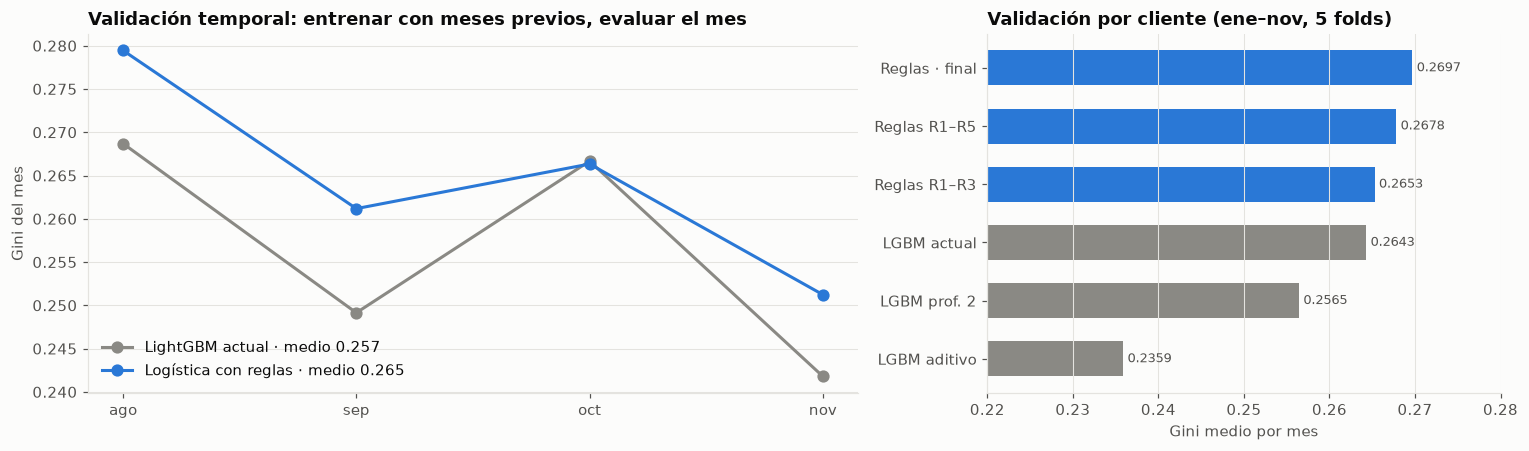

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
meses = ["ago", "sep", "oct", "nov"]; x = np.arange(4)
for name, col, lab in [("LGBM actual (5 semillas)", C["gray"], "LightGBM actual"), (FINAL, C["blue"], "Logística con reglas")]:
    ax.plot(x, tab.loc[name, meses].values, marker="o", markersize=7, color=col, label=f"{lab} · medio {tab.loc[name, 'medio']:.3f}")
ax.set_xticks(x, meses); ax.set_ylabel("Gini del mes"); ax.set_title("Validación temporal: entrenar con meses previos, evaluar el mes")
ax.legend(loc="lower left")
ax = axes[1]
orden = ["LGBM aditivo (stumps)", "LGBM profundidad 2", "LGBM actual (1 semilla)",
         "Logística · reglas R1–R3 + todas las variables", "Logística · reglas R1–R5 + todas las variables", FINAL]
etiquetas = ["LGBM aditivo", "LGBM prof. 2", "LGBM actual", "Reglas R1–R3", "Reglas R1–R5", "Reglas · final"]
vals = [RES_G[k] for k in orden]
ax.barh(range(len(vals)), vals, color=[C["gray"]] * 3 + [C["blue"]] * 3, height=0.6)
for i, v in enumerate(vals): ax.text(v + 0.0005, i, f"{v:.4f}", va="center", fontsize=8.5, color=C["ink2"])
ax.set_yticks(range(len(vals)), etiquetas); ax.set_xlim(0.22, 0.28); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Validación por cliente (ene–nov, 5 folds)"); ax.set_xlabel("Gini medio por mes")
fig.tight_layout(); savefig(fig, "20_comparacion_reglas")

**Lectura.** El modelo de reglas mejora al LightGBM en **ambos esquemas de validación**: ≈ +0.006 por cliente y ≈ +0.008
temporal, ganando o empatando en cada mes. Además pasa de ~400 árboles a ~30 coeficientes con significado de negocio.
Mezclarlo con el LightGBM no agrega nada (probado: ±0.0005), así que se adopta el modelo simple.

## 5. Robustez: ¿las reglas son estables en el tiempo?
Las reglas se descubrieron mirando toda la data, lo que podría inflar la validación. Control: el efecto de cada regla
se mide por separado en ene–jun y en jul–nov (diferencia de tasas dentro del segmento donde aplica).

In [17]:
X_ = X_reglas(dev)
seg = {
    "R1 alto × rec ≤180":            (X_.riesgo_alto == 1, X_.rec_le180),
    "R2 bajo × ≥3 productos":        ((X_.riesgo_bajo == 1) & (X_.R3_bajo_x_movil_tarjeta_x_prod2 == 0), X_.prod_ge3),
    "R3 bajo × móvil+tarjeta × ≥2":  ((X_.riesgo_bajo == 1) & (X_.prod_ge2 == 1), X_.movil_y_tarjeta),
    "R4 alto × branch":              (X_.riesgo_alto == 1, X_.branch),
    "R5 deuda>0.55 × sin móvil":     (dev.activo_movil == 0, (dev.ratio_deuda_ingresos > 0.55).astype(int)),
}
rows = {}
for k, (base_, x_) in seg.items():
    row = {}
    for lab, (lo, hi) in {"ene–jun": (1, 6), "jul–nov": (7, 11)}.items():
        m = base_.values & dev.t.between(lo, hi).values
        yy, xx = dev[TARGET].values[m], x_.values[m]
        row[f"Δ tasa {lab} (pp)"] = (yy[xx == 1].mean() - yy[xx == 0].mean()) * 100
    rows[k] = row
pd.DataFrame(rows).T.round(1)

,Δ tasa ene–jun (pp),Δ tasa jul–nov (pp)
R1 alto × rec ≤180,9.5000,8.9000
R2 bajo × ≥3 productos,10.2000,10.3000
R3 bajo × móvil+tarjeta × ≥2,12.5000,13.5000
R4 alto × branch,-3.5000,-3.8000
R5 deuda>0.55 × sin móvil,-3.8000,-5.9000


**Lectura.** Las cinco reglas tienen el mismo signo y magnitud similar en ambos semestres: son estructura estable del
generador, no ruido encontrado por búsqueda. La validación temporal (sección 4) ya entrena solo con meses previos y
confirma la mejora mes a mes.

## 6. ¿Cuál es el techo alcanzable?
Si el modelo de reglas fuera exactamente el generador, el Gini que se obtendría con la probabilidad verdadera es el
techo. Como la forma exacta es incierta, se calcula con dos versiones de la "verdad": la logística ajustada (efectos en
log-odds, algo suavizada por la regularización) y un modelo lineal de probabilidad (efectos aditivos en probabilidad,
la forma que sugieren las tablas de la sección 3.1). Además se simula cuánto varía el Gini **de un solo mes** (como
diciembre) aun con el modelo perfecto.

Techo si la verdad es logística (log-odds)    : 0.2697 ± 0.0054


Techo si la verdad es lineal en probabilidad  : 0.2745 ± 0.0034
Modelo final en validación por cliente:          0.2697


Gini de UN mes con el modelo perfecto: IC 95% [0.241, 0.300]


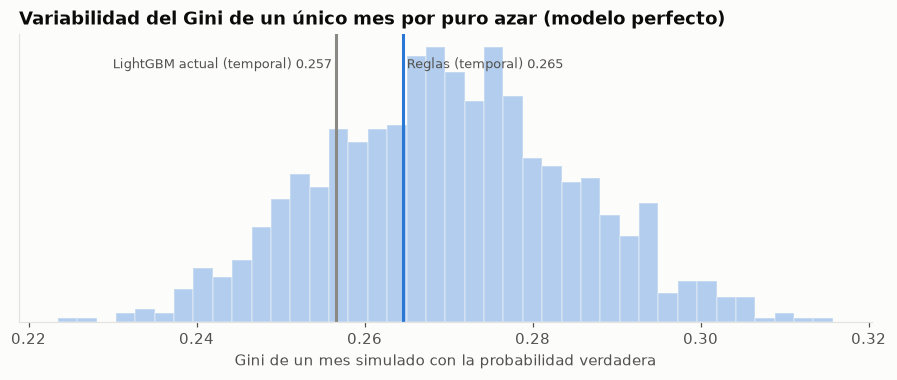

In [18]:
Xa = X_reglas(dev); sc = StandardScaler().fit(Xa)
lr_full = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Xa), dev[TARGET])
p_log = lr_full.predict_proba(sc.transform(Xa))[:, 1]
p_lin = np.clip(Ridge(alpha=1.0).fit(sc.transform(Xa), dev[TARGET]).predict(sc.transform(Xa)), 0.005, 0.995)
rng = np.random.default_rng(SEED)
for nombre, p_v in [("logística (log-odds)", p_log), ("lineal en probabilidad", p_lin)]:
    oraculo = [gini_mensual(p_v, dev.assign(**{TARGET: rng.binomial(1, p_v)})).mean() for _ in range(20)]
    print(f"Techo si la verdad es {nombre:24s}: {np.mean(oraculo):.4f} ± {np.std(oraculo):.4f}")
print(f"Modelo final en validación por cliente:          {RES_G[FINAL]:.4f}")
p_nov = p_lin[(dev.t == 11).values]
un_mes = np.array([gini(rng.binomial(1, p_nov), p_nov) for _ in range(1000)])
print(f"Gini de UN mes con el modelo perfecto: IC 95% [{np.quantile(un_mes, .025):.3f}, {np.quantile(un_mes, .975):.3f}]")

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(un_mes, bins=40, color=C["blue"], alpha=0.35, edgecolor=C["surface"])
for v, lab, col, ha in [(tab.loc["LGBM actual (5 semillas)", "medio"], "LightGBM actual (temporal)", C["gray"], "right"),
                        (tab.loc[FINAL, "medio"], "Reglas (temporal)", C["blue"], "left")]:
    ax.axvline(v, color=col, linewidth=2)
    ax.text(v, ax.get_ylim()[1] * 0.88, f" {lab} {v:.3f} ", color=C["ink2"], fontsize=8.5, ha=ha)
ax.set_xlabel("Gini de un mes simulado con la probabilidad verdadera"); ax.set_yticks([]); ax.grid(False)
ax.set_title("Variabilidad del Gini de un único mes por puro azar (modelo perfecto)")
savefig(fig, "21_techo_y_azar")

**Lectura.**
- El techo estimado está entre **≈ 0.270 y 0.274** según la forma asumida: el modelo de reglas (0.270) queda a
  **≤ 0.004 del techo**, mientras el LightGBM (0.264) quedaba a ≈ 0.01.
- Aun con el modelo perfecto, el Gini de **un solo mes** varía aproximadamente entre **0.24 y 0.30** por el azar de quién
  convierte. Un resultado de 0.28–0.30 en un mes puntual no implica un mejor modelo, y 0.7 solo es posible con fuga
  de información (p. ej. usar si el cliente aparece el mes siguiente, que no existe para diciembre).

## 7. Entrenamiento final y entrega

In [19]:
Xa, Xt = X_reglas(dev), X_reglas(tst)
assert list(Xa.columns) == list(Xt.columns)
sc = StandardScaler().fit(Xa)
modelo = LogisticRegression(C=0.1, max_iter=3000).fit(sc.transform(Xa), dev[TARGET])
pred = pd.Series(modelo.predict_proba(sc.transform(Xt))[:, 1], index=tst[ID].values)
submission = pd.DataFrame({ID: test[ID].values, "prediccion": pred.loc[test[ID].values].values})

checks = {
    "columnas exactas [id_cliente, prediccion]": list(submission.columns) == list(sample_sub.columns),
    "mismo número de filas que test": len(submission) == len(test),
    "mismo orden de id_cliente que test y sample_submission": submission[ID].equals(test[ID]) and submission[ID].equals(sample_sub[ID]),
    "sin nulos": submission["prediccion"].notna().all(),
    "probabilidades en [0, 1]": submission["prediccion"].between(0, 1).all(),
    "predicciones no constantes": submission["prediccion"].nunique() > 1,
}
assert all(checks.values()), checks
submission.to_csv("submission_v2.csv", index=False)
print(pd.Series(checks, name="OK").to_string())
anterior = pd.read_csv("submission.csv")
print(f"\nGuardado: submission_v2.csv ({len(submission):,} filas) | prob. media {submission.prediccion.mean():.4f} "
      f"(tasa nov {dev.loc[dev.t == 11, TARGET].mean():.4f})")
print(f"Correlación de rangos con la entrega anterior (LightGBM): {submission.prediccion.corr(anterior.prediccion, method='spearman'):.3f}")

columnas exactas [id_cliente, prediccion]                 True
mismo número de filas que test                            True
mismo orden de id_cliente que test y sample_submission    True
sin nulos                                                 True
probabilidades en [0, 1]                                  True
predicciones no constantes                                True

Guardado: submission_v2.csv (9,900 filas) | prob. media 0.1404 (tasa nov 0.1515)
Correlación de rangos con la entrega anterior (LightGBM): 0.923


In [20]:
json.dump({"modelo_final": "Regresión logística con reglas de negocio (C=0.1, variables estandarizadas)",
           "variables": list(Xa.columns),
           "coeficientes_estandarizados": dict(zip(Xa.columns, modelo.coef_[0].round(5).tolist())),
           "gini_validacion_por_cliente": RES_G[FINAL],
           "gini_validacion_temporal": tab.loc[FINAL, ["ago", "sep", "oct", "nov", "medio"]].to_dict()},
          open(ART_DIR / "modelo_reglas.json", "w"), indent=2, ensure_ascii=False, default=float)

## 8. ¿Se puede subir más? Pruebas adicionales

Después de fijar el modelo se probaron todas las hipótesis específicas del caso que podrían dejar señal sin explotar
(scripts exploratorios con la misma validación por cliente; ninguna supera al modelo final):

| Hipótesis | Prueba | Resultado |
|---|---|---|
| Fragilidad: los sobrevivientes antiguos tienen menos propensión de la que explican sus variables | residuo por `meses_en_panel` y por hazard acumulado (`meses_en_panel` × p) | \|z\| ≤ 1.8 en todos los grupos → no existe |
| Las reglas cambian en el tiempo | efecto de R1–R5 mes a mes | estables, sin tendencia → no conviene ponderar meses recientes |
| `dias_ultima_interaccion` interactúa con los segmentos | residuo por deciles × riesgo, cambio vs mes previo | ruido |
| Umbrales ocultos en variables continuas | mejor corte de 12 variables dentro de 37 segmentos (444 búsquedas) vs residuos permutados | máximo real 3.7 < máximo bajo azar 4.5–5.9 |
| Forma aditiva en probabilidad (MLE con *link* identidad, IRLS) | validación por cliente / temporal | 0.2690 / 0.2632 (no mejora) |
| Regularización de la logística (C = 0.01, 0.1, 1) | validación por cliente | 0.2697–0.2698 (indiferente) |
| Mezclas con LightGBM (con y sin reglas como variables) | validación por cliente | 0.2697–0.2698 (indiferente) |

**Conclusión:** el modelo contiene toda la estructura detectable; lo que resta hasta el techo (≤ 0.004) es error de
estimación irreducible con 110 mil filas.

### 8.1 ¿Cómo se compara un "0.28"? Mismo modelo, distintos esquemas de validación

In [21]:
from sklearn.model_selection import StratifiedKFold, train_test_split
FEAT_TODAS = FEATURES_LGB + ["dias_ultima_interaccion"]
def f_lgb_defecto(a, b):     # LightGBM "por defecto" con todas las columnas
    return lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, verbose=-1, n_jobs=N_JOBS, random_state=0) \
              .fit(a[FEAT_TODAS], a[TARGET]).predict_proba(b[FEAT_TODAS])[:, 1]
modelos = {"Reglas (final)": fp_final, "LightGBM notebook 02": make_lgb(LGB_PARAMS), "LightGBM por defecto": f_lgb_defecto}
esquemas = {}
for nombre, f in modelos.items():
    r = {}
    oof = np.zeros(len(dev))
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=0).split(dev, dev[TARGET]):
        oof[va_i] = f(dev.iloc[tr_i], dev.iloc[va_i])
    r["KFold por filas (mismo cliente en ambos lados)"] = gini(dev[TARGET], oof)
    a, b = train_test_split(dev, test_size=0.2, random_state=SEED, stratify=dev[TARGET]); r["holdout 80/20 por filas"] = gini(b[TARGET], f(a, b))
    for m, lab in [(8, "solo agosto"), (11, "solo noviembre")]:
        r[f"temporal · {lab}"] = gini(dev.loc[dev.t == m, TARGET], f(dev[dev.t < m], dev[dev.t == m]))
    r["temporal · media ago–nov"] = RES_T[FINAL].mean() if nombre == "Reglas (final)" else \
        (RES_T["LGBM actual (5 semillas)"].mean() if nombre == "LightGBM notebook 02" else
         np.mean([gini(dev.loc[dev.t == m, TARGET], f(dev[dev.t < m], dev[dev.t == m])) for m in (8, 9, 10, 11)]))
    r["dentro de muestra (fuga)"] = gini(dev[TARGET], f(dev, dev))
    esquemas[nombre] = r
pd.DataFrame(esquemas)

,Reglas (final),LightGBM notebook 02,LightGBM por defecto
KFold por filas (mismo cliente en ambos lados),0.2687,0.2645,0.2473
holdout 80/20 por filas,0.2648,0.2631,0.2384
temporal · solo agosto,0.2794,0.2678,0.2492
temporal · solo noviembre,0.2512,0.2424,0.2085
temporal · media ago–nov,0.2645,0.2566,0.2273
dentro de muestra (fuga),0.2749,0.3001,0.6350


**Lectura.** El modelo de reglas gana en **todos** los esquemas. Un "0.28" es exactamente lo que obtiene nuestro
modelo si se valida solo en agosto (≈ 0.279), y un "0.6–0.7" es lo que da un LightGBM evaluado sobre su propia data
de entrenamiento. Para comparar modelos del equipo hay que usar el **mismo esquema**: la media temporal ago–nov (o la
validación por cliente), nunca un mes suelto ni datos vistos en el entrenamiento.

### 8.2 Trampa del generador en `dias_ultima_interaccion`

In [22]:
full = pd.concat([dev, tst]).sort_values([ID, "t"])
full["cambia_vs_mes_previo"] = full.groupby(ID).dias_ultima_interaccion.diff().ne(0) & full.meses_en_panel.gt(0)
full["igual_a_dias_ult_transaccion"] = full.dias_ultima_interaccion.eq(full.dias_ultima_transaccion)
trampa = full.groupby("t")[["igual_a_dias_ult_transaccion", "cambia_vs_mes_previo"]].mean().T
trampa.columns = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic (test)"]
trampa

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic (test)
igual_a_dias_ult_transaccion,1.0000,0.9094,0.8189,0.7282,0.6369,0.5468,0.4566,0.3654,0.2760,0.1843,0.0940,0.0026
cambia_vs_mes_previo,0.0000,0.0810,0.2014,0.3689,0.4353,0.5330,0.6795,0.6880,0.7820,0.7762,0.9048,0.8113


**Lectura.** La fracción de filas con `dias_ultima_interaccion` = `dias_ultima_transaccion` cae **exactamente 1/11 por
mes** (100% en enero → 9% en noviembre → 0.3% en diciembre): es ruido inyectado en función del mes, sin relación con
la conversión. Cualquier modelo que use esta variable o derivadas (p. ej. "interactuó", diferencias con el mes previo)
recibe en diciembre una distribución que **nunca vio en entrenamiento**. El modelo final la excluye.

## 9. Conclusiones

1. **El techo de ≈ 0.26 era del método, no de la data.** El *boosting* aprendía las interacciones partiendo el espacio
   en muchas hojas pequeñas y perdía ≈ 0.01 de Gini por varianza de estimación.
2. **La señal es un sistema de cinco reglas con umbrales exactos** (180 días, 3 productos, 0.55 de deuda), aditivas en
   probabilidad, más efectos menores de ingresos, antigüedad, edad, saldo y distancia. R4 y R5 solo aparecieron con la
   minería sistemática de residuos.
3. **Una logística con esas reglas mejora en ambas validaciones**: 0.264 → 0.270 (por cliente) y 0.257 → 0.264
   (temporal), con ~30 coeficientes interpretables. Queda a ≤ 0.004 del techo estimado (≈ 0.270–0.274).
4. **Expectativa para diciembre:** Gini ≈ 0.265–0.27, con ± 0.03 de azar. El azar de un solo mes (IC 95% ≈ 0.24–0.30 incluso con el modelo
   perfecto) domina las diferencias entre equipos que estén cerca del techo.
5. **Se agotaron las hipótesis específicas** (fragilidad, deriva de reglas, umbrales ocultos, forma funcional,
   mezclas): ninguna mejora, y el modelo gana en todos los esquemas de validación. `dias_ultima_interaccion` es una
   trampa con deriva artificial hacia diciembre y debe excluirse.
6. **Valor de negocio:** las reglas son accionables directamente: priorizar clientes de riesgo bajo con app y tarjeta y
   ≥ 2 productos; reactivar clientes de riesgo alto con transacciones en el último semestre; no invertir en clientes de
   riesgo alto adquiridos en agencia ni en sobreendeudados sin app.